***Regression***

In [ ]:
!apt-get -qq update > /dev/null && apt-get -qq install -y texlive-latex-extra texlive-fonts-recommended cm-super dvipng > /dev/null

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
^C


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

df = pd.read_csv('outlier_checked_data.csv')
print(df.shape)
print('Missing:', df.isna().sum().sum())

(31845, 19)
Missing: 0


***1. Experimental Setup***

In [ ]:
# 1a. inputs and targets
arrival_categorical = ['fire_type', 'building_type', 'district', 'region']
arrival_numeric = ['dispatch_hour', 'month', 'year']
water_categorical = arrival_categorical + ['fire_cause', 'fire_result']
water_numeric = arrival_numeric + ['arrival_min', 'foam_kg', 'dry_powder_kg']

X_arrival = pd.get_dummies(df[arrival_categorical + arrival_numeric], columns=arrival_categorical, drop_first=True, dtype=int)
X_water = pd.get_dummies(df[water_categorical + water_numeric], columns=water_categorical, drop_first=True, dtype=int)
y_arrival = df['arrival_min']
y_water = df['water_m3']
print('X_arrival:', X_arrival.shape, ' X_water:', X_water.shape)

X_arrival: (31845, 82)  X_water: (31845, 119)


In [ ]:
# 1b. 70/30 train-test split
X_arrival_train, X_arrival_test, y_arrival_train, y_arrival_test = train_test_split(X_arrival, y_arrival, test_size=0.3, random_state=42)
X_water_train, X_water_test, y_water_train, y_water_test = train_test_split(X_water, y_water, test_size=0.3, random_state=42)

print('Train:', len(X_arrival_train), ' Test:', len(X_arrival_test))
print('Arrival mean  train:', round(y_arrival_train.mean(), 2), ' test:', round(y_arrival_test.mean(), 2))
print('Water mean    train:', round(y_water_train.mean(), 2), ' test:', round(y_water_test.mean(), 2))

Train: 22291  Test: 9554
Arrival mean  train: 6.08  test: 5.96
Water mean    train: 8.49  test: 8.33


***2. Regression Models***

In [ ]:
# 2a. arrival time models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

linear_arrival = LinearRegression()
linear_arrival.fit(X_arrival_train, y_arrival_train)
tree_arrival = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_arrival.fit(X_arrival_train, y_arrival_train)

arrival_pred_linear = linear_arrival.predict(X_arrival_test)
arrival_pred_tree = tree_arrival.predict(X_arrival_test)
print(pd.DataFrame({'Actual': y_arrival_test.values[:5], 'Linear': arrival_pred_linear[:5], 'Tree': arrival_pred_tree[:5]}).round(1))

   Actual  Linear  Tree
0    23.0    10.0   9.0
1     6.0     5.0   4.3
2     3.0     4.7   4.3
3     8.0    10.1   9.0
4     5.0     4.8   4.3


In [ ]:
# 2b. water amount models (log scale)
log_cols = ['arrival_min', 'foam_kg', 'dry_powder_kg']
X_water_train_log = X_water_train.copy()
X_water_test_log = X_water_test.copy()
X_water_train_log[log_cols] = np.log1p(X_water_train_log[log_cols])
X_water_test_log[log_cols] = np.log1p(X_water_test_log[log_cols])

linear_water = LinearRegression()
linear_water.fit(X_water_train_log, np.log1p(y_water_train))
tree_water = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_water.fit(X_water_train_log, np.log1p(y_water_train))

water_pred_linear = np.expm1(linear_water.predict(X_water_test_log)).clip(0)
water_pred_tree = np.expm1(tree_water.predict(X_water_test_log)).clip(0)
print(pd.DataFrame({'Actual': y_water_test.values[:5], 'Linear': water_pred_linear[:5], 'Tree': water_pred_tree[:5]}).round(1))

   Actual  Linear  Tree
0     2.0     2.2   1.7
1     1.0     2.9   1.2
2     2.0     0.7   0.8
3     3.0     1.9   1.7
4     2.0     1.2   1.2


***3. Performance Evaluation***

In [ ]:
# 3a. RMSE, MAPE and correlation coefficient
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

def evaluate(actual, predicted):
    actual = np.array(actual)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    nonzero = actual > 0
    mape = mean_absolute_percentage_error(actual[nonzero], predicted[nonzero]) * 100
    r = np.corrcoef(actual, predicted)[0, 1]
    return [round(rmse, 2), round(mape, 1), round(r, 3)]

normal = y_water_test.values <= 600
results = pd.DataFrame([evaluate(y_arrival_test, arrival_pred_linear),
                        evaluate(y_arrival_test, arrival_pred_tree),
                        evaluate(y_water_test, water_pred_linear),
                        evaluate(y_water_test, water_pred_tree),
                        evaluate(y_water_test[normal], water_pred_linear[normal]),
                        evaluate(y_water_test[normal], water_pred_tree[normal])],
                       columns=['RMSE', 'MAPE (%)', 'r'],
                       index=['Arrival - Linear', 'Arrival - Tree', 'Water - Linear', 'Water - Tree',
                              'Water <= 600 - Linear', 'Water <= 600 - Tree'])
print(results)

                         RMSE  MAPE (%)      r
Arrival - Linear         4.32      45.7  0.557
Arrival - Tree           4.17      45.0  0.599
Water - Linear         305.93     193.4  0.518
Water - Tree           307.52     205.6  0.176
Water <= 600 - Linear   23.20     193.4  0.483
Water <= 600 - Tree     23.56     205.7  0.355


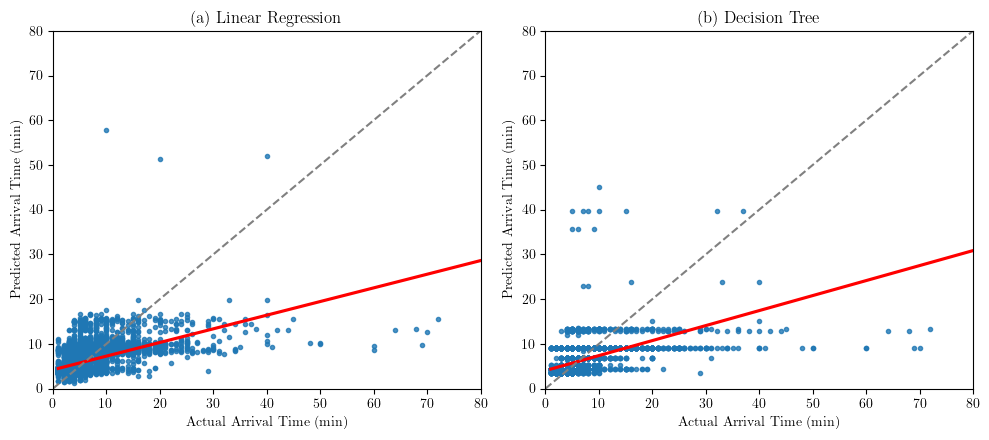

In [ ]:
# 3b. actual vs predicted: arrival time
import matplotlib.pyplot as plt
import seaborn as sns
import os
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "serif"
os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(10, 4.5))

# left: linear regression (points + red regression line, gray = perfect prediction)
plt.subplot(1, 2, 1)
sns.regplot(x=y_arrival_test, y=arrival_pred_linear, ci=None, marker=".", line_kws={"color": "red"})
plt.plot([0, 80], [0, 80], "--", color="gray")
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.xlabel("Actual Arrival Time (min)")
plt.ylabel("Predicted Arrival Time (min)")
plt.title("(a) Linear Regression")

# right: decision tree
plt.subplot(1, 2, 2)
sns.regplot(x=y_arrival_test, y=arrival_pred_tree, ci=None, marker=".", line_kws={"color": "red"})
plt.plot([0, 80], [0, 80], "--", color="gray")
plt.xlim(0, 80)
plt.ylim(0, 80)
plt.xlabel("Actual Arrival Time (min)")
plt.ylabel("Predicted Arrival Time (min)")
plt.title("(b) Decision Tree")

plt.tight_layout()
plt.savefig("figures/regression_arrival.png", dpi=300)
plt.show()

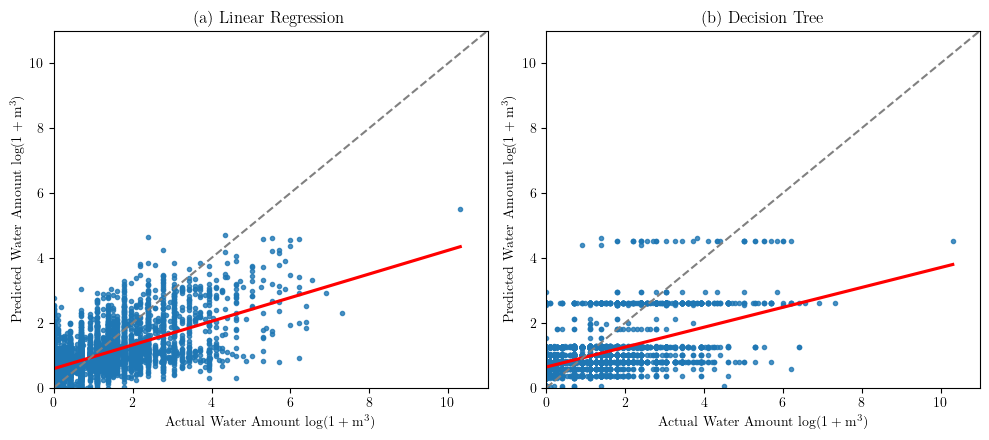

In [ ]:
# 3c. actual vs predicted: water amount (log scale)
plt.figure(figsize=(10, 4.5))

# left: linear regression
plt.subplot(1, 2, 1)
sns.regplot(x=np.log1p(y_water_test), y=np.log1p(water_pred_linear), ci=None, marker=".", line_kws={"color": "red"})
plt.plot([0, 11], [0, 11], "--", color="gray")
plt.xlim(0, 11)
plt.ylim(0, 11)
plt.xlabel(r"Actual Water Amount $\log(1 + \mathrm{m}^3)$")
plt.ylabel(r"Predicted Water Amount $\log(1 + \mathrm{m}^3)$")
plt.title("(a) Linear Regression")

# right: decision tree
plt.subplot(1, 2, 2)
sns.regplot(x=np.log1p(y_water_test), y=np.log1p(water_pred_tree), ci=None, marker=".", line_kws={"color": "red"})
plt.plot([0, 11], [0, 11], "--", color="gray")
plt.xlim(0, 11)
plt.ylim(0, 11)
plt.xlabel(r"Actual Water Amount $\log(1 + \mathrm{m}^3)$")
plt.ylabel(r"Predicted Water Amount $\log(1 + \mathrm{m}^3)$")
plt.title("(b) Decision Tree")

plt.tight_layout()
plt.savefig("figures/regression_water.png", dpi=300)
plt.show()

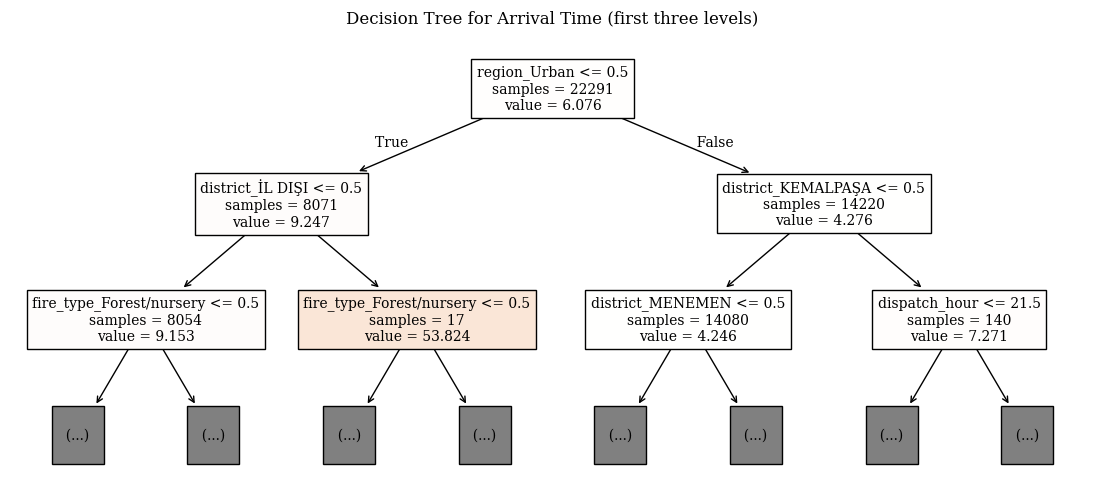

In [ ]:
# 3d. decision tree for arrival time (first three levels)
from sklearn.tree import plot_tree

plt.rcParams["text.usetex"] = False  # column names have "_", which LaTeX cannot print

plt.figure(figsize=(14, 6))
plot_tree(tree_arrival, max_depth=2, feature_names=X_arrival.columns, filled=True, impurity=False, fontsize=10)
plt.title("Decision Tree for Arrival Time (first three levels)")
plt.savefig("figures/tree_arrival.png", dpi=300)
plt.show()